In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd

# Option A paths (using your mounted Google Drive file system paths):
# Note: Please adjust the folder paths below if your files are in a different Drive folder.
TRAIN_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTrain+.txt"
TEST_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTest+.txt"


In [19]:
import gdown

# Extract the file IDs from your Google Drive links
train_id = '1gEgDi6QPGiiK0ttYiBNk55ZTgUykX2UT'
test_id = '1YHacgPxgXudvMJyfLVzXkJl2OuY8D_QD'

# Define local destination paths
TRAIN_PATH = '/content/drive/MyDrive/KDDTrain+.txt'
TEST_PATH = '/content/drive/MyDrive/KDDTest+.txt'

# Download the files programmatically
# gdown.download(id=train_id, output=TRAIN_PATH, quiet=False)
# gdown.download(id=test_id, output=TEST_PATH, quiet=False)


In [21]:
def load_data(path):
    """Load an NSL-KDD file (no header) and name its columns."""
    try:
        df = pd.read_csv(path, names=COLUMNS)
    except FileNotFoundError:
        raise FileNotFoundError(f"File not found: {path}. Check the path.")
    if df.shape[1] != len(COLUMNS):
        raise ValueError(f"Expected {len(COLUMNS)} columns, got {df.shape[1]}.")
    return df

# Using the local paths downloaded by gdown in the previous step
train = load_data('/content/drive/MyDrive/KDDTrain+.txt')
test = load_data('/content/drive/MyDrive/KDDTest+.txt')
print(train.shape, test.shape)
display(train.head())


(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0\ttcp\tftp_data\tSF\t491\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0\tudp\tother\tSF\t146\t0\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0\ttcp\tprivate\tS0\t0\t0\t0\t0\t0\t0\t0\t0\t0...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0\ttcp\thttp\tSF\t232\t8153\t0\t0\t0\t0\t0\t1\...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0\ttcp\thttp\tSF\t199\t420\t0\t0\t0\t0\t0\t1\t...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
# audit checks

# Load train and test (tab-separated, no header)
train = pd.read_csv(TRAIN_PATH, names=COLUMNS, sep="\t")
test = pd.read_csv(TEST_PATH, names=COLUMNS, sep="\t")

# Quality checks for train and test
for name, df in [("train", train), ("test", test)]:
    is_normal = df["label"].str.lower() == "normal"   # works for 'normal' and 'Normal'
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print("missing values:", df.isna().sum().sum())
    print("duplicate rows:", df.duplicated().sum())
    print("normal %:", round(is_normal.mean() * 100, 2))
    print("attack %:", round((~is_normal).mean() * 100, 2))
    print()

# Columns that contain missing values (test file)
print("Columns with missing values:")
print(test.isna().sum()[lambda s: s > 0])

# Label counts
print("\nTrain label counts:")
print(train["label"].value_counts())
print("\nTest label counts:")
print(test["label"].value_counts())

# Categorical columns (train)
for col in ["protocol_type", "service", "flag"]:
    print(f"\n{col}: {train[col].nunique()} distinct values")

    test.isna().sum()[lambda s: s > 0]

--- train ---
shape: (125973, 43)
missing values: 0
duplicate rows: 0
normal %: 53.46
attack %: 46.54

--- test ---
shape: (22544, 43)
missing values: 22544
duplicate rows: 3
normal %: 43.08
attack %: 56.92

Columns with missing values:
difficulty    22544
dtype: int64

Train label counts:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

Test label counts:
label
Attack    12833
Normal     9711
Name: count, dtype: int64

protocol_type: 3 

In [1]:
!pip install -q gradio

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42   # a fixed number, so the results are the same every time
print("Libraries ready")

Libraries ready


In [2]:
# OPTION A: you uploaded the files with the folder icon on the left of Colab
TRAIN_PATH = "/content/drive/MyDrive/KDDTrain+.txt"
TEST_PATH = "/content/drive/MyDrive/KDDTest+.txt"

# OPTION B: the files are in Google Drive.
# Remove the # at the start of the next 4 lines and put a # in front of the 2 lines above.
# from google.colab import drive
# drive.mount("/content/drive")
# TRAIN_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTrain+.txt"
# TEST_PATH = "/content/drive/MyDrive/nids_project/data/raw/KDDTest+.txt"

In [3]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty",
]

FEATURES = COLUMNS[:41]                                # the 41 input columns
CATEGORICAL = ["protocol_type", "service", "flag"]     # text columns
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]


def load_data(path):
    """Read one NSL-KDD file (tab-separated, no header) and name its columns."""
    try:
        df = pd.read_csv(path, names=COLUMNS, sep="\t")
    except FileNotFoundError:
        raise FileNotFoundError(f"File not found: {path}. Check the path in Step 2.")
    if df["label"].isna().all():
        raise ValueError("All labels are empty: wrong separator or wrong file.")
    return df


train_raw = load_data(TRAIN_PATH)
test_raw = load_data(TEST_PATH)
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
train_raw.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [4]:
FAMILY_MAP = {
    "normal": "Normal",
    # DoS: flooding a server so it stops working
    "neptune": "DoS", "smurf": "DoS", "back": "DoS", "teardrop": "DoS", "pod": "DoS", "land": "DoS",
    # Probe: scanning a network to find weaknesses
    "satan": "Probe", "ipsweep": "Probe", "portsweep": "Probe", "nmap": "Probe",
    # R2L: an outsider trying to get access
    "warezclient": "R2L", "guess_passwd": "R2L", "warezmaster": "R2L", "imap": "R2L",
    "ftp_write": "R2L", "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    # U2R: a normal user trying to get admin rights
    "buffer_overflow": "U2R", "rootkit": "U2R", "loadmodule": "U2R", "perl": "U2R",
}


def clean_data(df, name):
    """Clean one DataFrame and print a short report."""
    print(f"--- Cleaning {name} ---")
    df = df.copy()
    rows_before = len(df)

    # 1. Remove the difficulty column
    df = df.drop(columns=["difficulty"], errors="ignore")

    # 2. Tidy text columns
    for col in CATEGORICAL + ["label"]:
        df[col] = df[col].astype(str).str.strip()
    df["label"] = df["label"].str.lower()          # 'Normal' and 'normal' become the same

    # 3. Number columns must be numbers
    for col in NUMERIC:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # 4. Missing values
    n_missing = int(df.isna().any(axis=1).sum())
    print("Rows with missing values removed:", n_missing)
    df = df.dropna()

    # 5. Duplicate rows
    n_dup = int(df.duplicated().sum())
    print("Duplicate rows removed:", n_dup)
    df = df.drop_duplicates()

    # 6. Impossible values (negative numbers)
    negative = (df[NUMERIC] < 0).any(axis=1)
    print("Rows with negative values removed:", int(negative.sum()))
    df = df[~negative]

    # 7. Targets
    df["target"] = (df["label"] != "normal").astype(int)      # 0 = normal, 1 = attack
    df["family"] = df["label"].map(FAMILY_MAP)                # empty for the test file (only Normal/Attack)

    print(f"Rows: {rows_before} -> {len(df)}")
    return df.reset_index(drop=True)


train = clean_data(train_raw, "train")
test = clean_data(test_raw, "test")

# 8. Columns that never change carry no information, so we remove them
constant_cols = [c for c in NUMERIC if train[c].nunique() == 1]
print("\nConstant columns removed:", constant_cols)
train = train.drop(columns=constant_cols)
test = test.drop(columns=constant_cols)
NUMERIC = [c for c in NUMERIC if c not in constant_cols]
FEATURES = CATEGORICAL + NUMERIC

print("\nFinal number of input features:", len(FEATURES))
print("Train normal/attack:", train["target"].value_counts().to_dict())
print("Test normal/attack:", test["target"].value_counts().to_dict())

--- Cleaning train ---
Rows with missing values removed: 0
Duplicate rows removed: 0
Rows with negative values removed: 0
Rows: 125973 -> 125973
--- Cleaning test ---
Rows with missing values removed: 0
Duplicate rows removed: 3
Rows with negative values removed: 0
Rows: 22544 -> 22541

Constant columns removed: ['num_outbound_cmds']

Final number of input features: 40
Train normal/attack: {0: 67343, 1: 58630}
Test normal/attack: {1: 12830, 0: 9711}


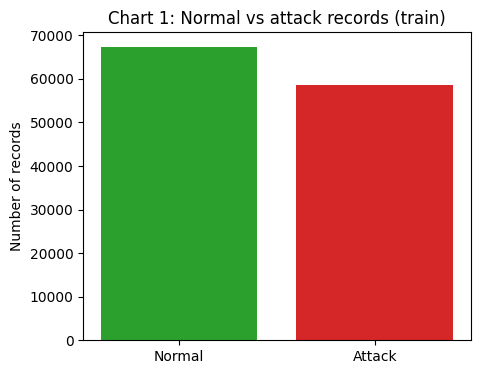

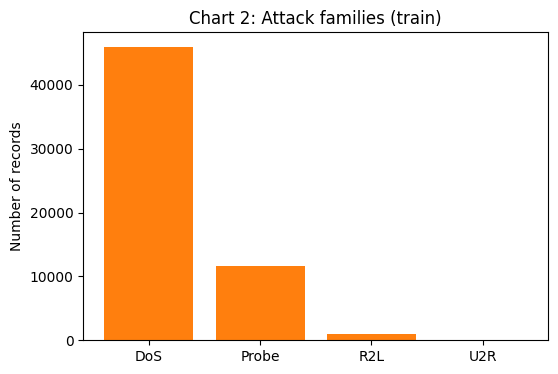

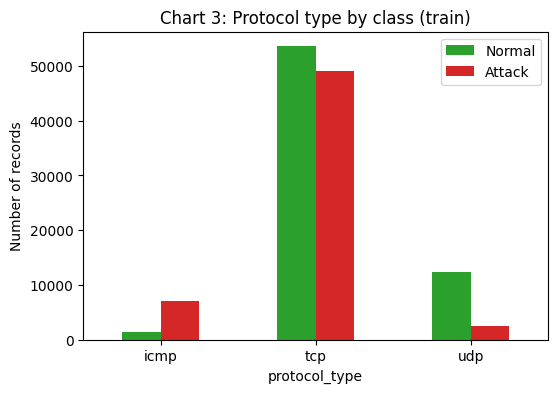

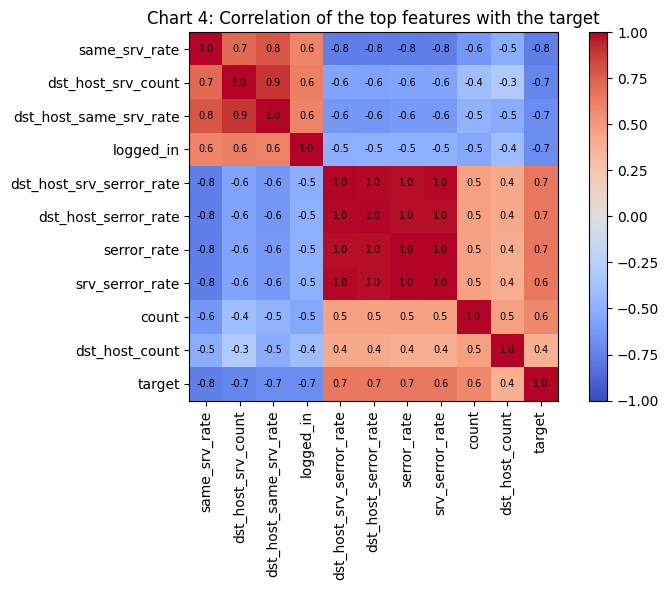

In [5]:
# Chart 1: normal vs attack
counts = train["target"].value_counts().sort_index()
plt.figure(figsize=(5, 4))
plt.bar(["Normal", "Attack"], counts.values, color=["tab:green", "tab:red"])
plt.title("Chart 1: Normal vs attack records (train)")
plt.ylabel("Number of records")
plt.show()

# Chart 2: attack families
fam = train[train["target"] == 1]["family"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(fam.index, fam.values, color="tab:orange")
plt.title("Chart 2: Attack families (train)")
plt.ylabel("Number of records")
plt.show()

# Chart 3: protocol type for normal and attack records
proto = pd.crosstab(train["protocol_type"], train["target"])
proto.columns = ["Normal", "Attack"]
proto.plot(kind="bar", figsize=(6, 4), color=["tab:green", "tab:red"])
plt.title("Chart 3: Protocol type by class (train)")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.show()

# Chart 4: the 10 numeric features most related to the target
top_cols = train[NUMERIC].corrwith(train["target"]).abs().sort_values(ascending=False).head(10).index.tolist()
corr = train[top_cols + ["target"]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Chart 4: Correlation of the top features with the target")
plt.tight_layout()
plt.show()

In [6]:
X_all = train[FEATURES]
y_all = train["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE
)

X_test = test[FEATURES]
y_test = test["target"]

print("Training part:  ", X_train.shape)
print("Validation part:", X_val.shape)
print("Official test:  ", X_test.shape)


def build_pipeline(model):
    """Text columns -> numbers (one-hot), then the model."""
    prep = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough",     # number columns are used as they are
    )
    return Pipeline([("prep", prep), ("model", model)])

Training part:   (100778, 40)
Validation part: (25195, 40)
Official test:   (22541, 40)


In [8]:
results = []   # every result goes into this list


def evaluate(name, model, X, y, split_name):
    """Print the scores and the confusion matrix, and store the results."""
    pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    row = {
        "Model": name,
        "Data": split_name,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "False positive rate": fp / (fp + tn),
    }
    results.append(row)
    print(f"{name} on {split_name}: " + ", ".join(f"{k}={v:.4f}" for k, v in row.items() if k not in ("Model", "Data")))
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Normal", "Attack"], cmap="Blues")
    plt.title(f"{name} - {split_name}")
    plt.show()

Exp 1: Decision Tree on validation: Accuracy=0.9985, Precision=0.9981, Recall=0.9986, F1=0.9983, False positive rate=0.0016


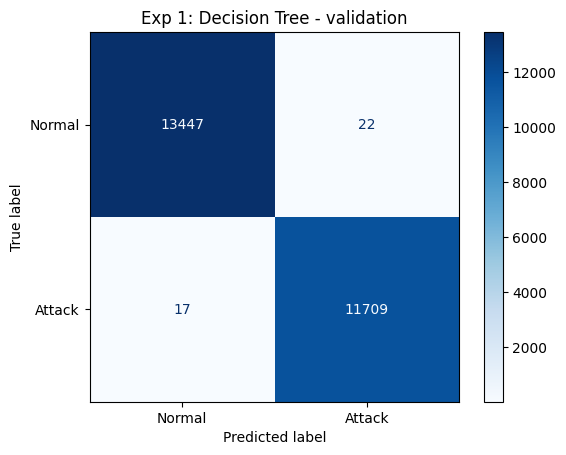

Exp 1: Decision Tree on official test: Accuracy=0.7902, Precision=0.9178, Recall=0.6935, F1=0.7901, False positive rate=0.0821


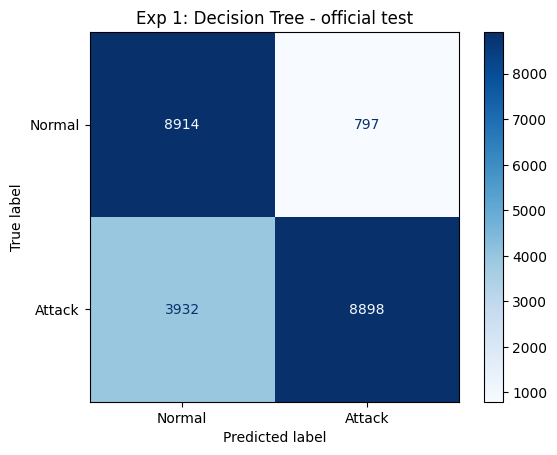

In [9]:
# Experiment 1: Decision Tree (baseline)
tree_model = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
tree_model.fit(X_train, y_train)
evaluate("Exp 1: Decision Tree", tree_model, X_val, y_val, "validation")
evaluate("Exp 1: Decision Tree", tree_model, X_test, y_test, "official test")

Exp 2: Random Forest on validation: Accuracy=0.9990, Precision=0.9995, Recall=0.9985, F1=0.9990, False positive rate=0.0004


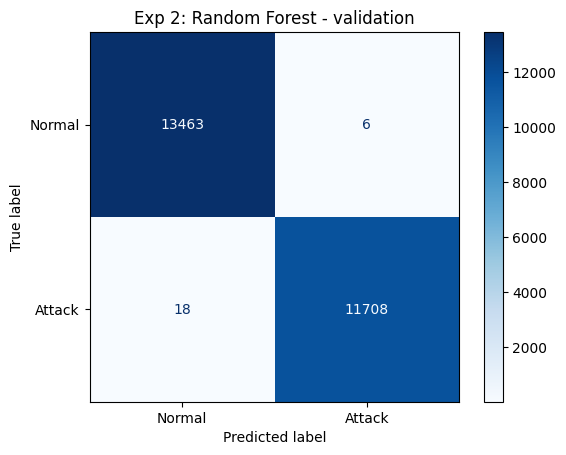

Exp 2: Random Forest on official test: Accuracy=0.7814, Precision=0.9692, Recall=0.6362, F1=0.7682, False positive rate=0.0267


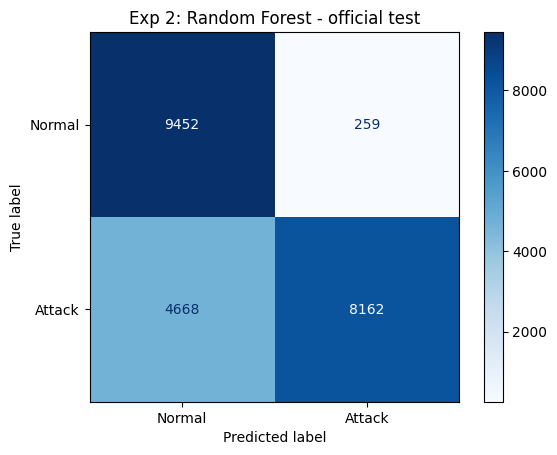

In [10]:
# Experiment 2: Random Forest (100 trees)
rf_model = build_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
rf_model.fit(X_train, y_train)
evaluate("Exp 2: Random Forest", rf_model, X_val, y_val, "validation")
evaluate("Exp 2: Random Forest", rf_model, X_test, y_test, "official test")

Exp 3: Random Forest balanced on validation: Accuracy=0.9989, Precision=0.9996, Recall=0.9981, F1=0.9988, False positive rate=0.0004


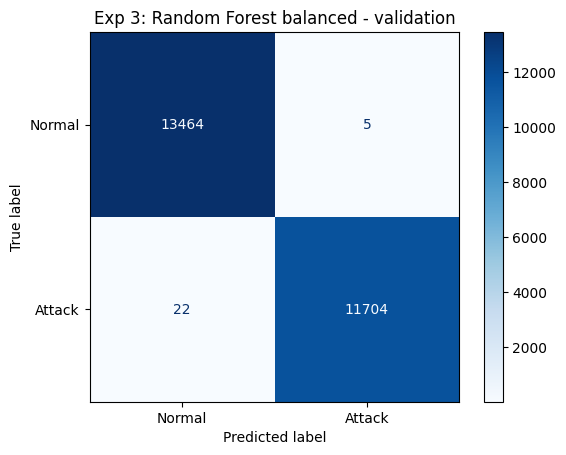

Exp 3: Random Forest balanced on official test: Accuracy=0.7612, Precision=0.9669, Recall=0.6010, F1=0.7413, False positive rate=0.0272


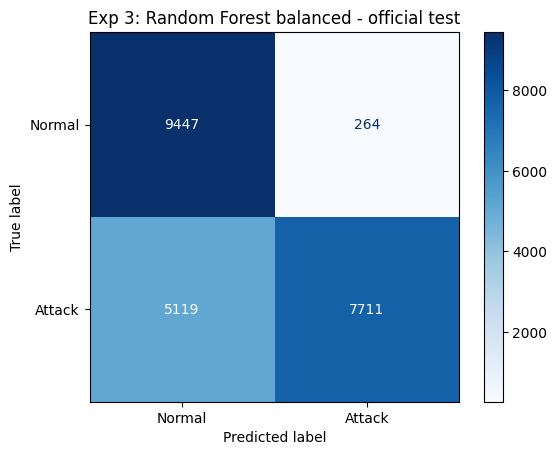

In [11]:
# Experiment 3: Random Forest (200 trees, balanced class weights)
rf_model_2 = build_pipeline(RandomForestClassifier(
    n_estimators=200, min_samples_leaf=2, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=-1))
rf_model_2.fit(X_train, y_train)
evaluate("Exp 3: Random Forest balanced", rf_model_2, X_val, y_val, "validation")
evaluate("Exp 3: Random Forest balanced", rf_model_2, X_test, y_test, "official test")

In [12]:
# Results table: copy this into your report
results_table = pd.DataFrame(results).round(4)
results_table

,Model,Data,Accuracy,Precision,Recall,F1,False positive rate
0,Exp 1: Decision Tree,validation,0.9985,0.9981,0.9986,0.9983,0.0016
1,Exp 1: Decision Tree,official test,0.7902,0.9178,0.6935,0.7901,0.0821
2,Exp 2: Random Forest,validation,0.9990,0.9995,0.9985,0.9990,0.0004
3,Exp 2: Random Forest,official test,0.7814,0.9692,0.6362,0.7682,0.0267
4,Exp 3: Random Forest balanced,validation,0.9989,0.9996,0.9981,0.9988,0.0004
5,Exp 3: Random Forest balanced,official test,0.7612,0.9669,0.6010,0.7413,0.0272


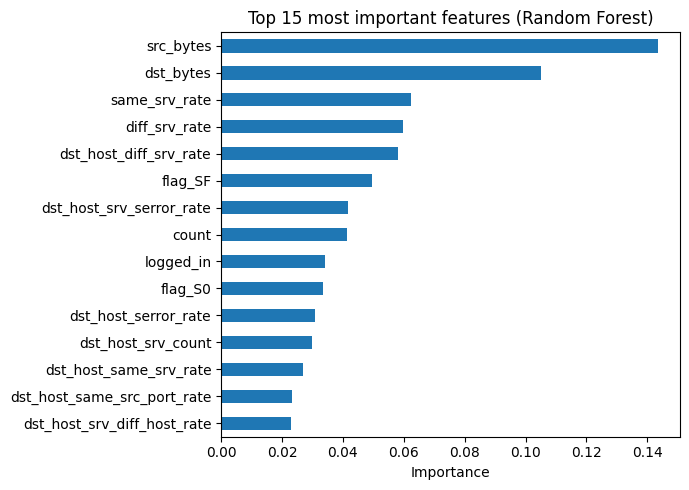

In [13]:
# The final model is the Random Forest from Experiment 2.
# To use Experiment 3 instead, change this line to: final_model = rf_model_2
final_model = rf_model

prep = final_model.named_steps["prep"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
importances = pd.Series(final_model.named_steps["model"].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(7, 5))
top15[::-1].plot(kind="barh", color="tab:blue")
plt.title("Top 15 most important features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [15]:
ATTACK_THRESHOLD = 0.5      # attack probability at or above this = "Attack"


def alert_level(prob):
    """Turn an attack probability into a simple alert level."""
    if prob >= 0.90:
        return "High"
    if prob >= 0.50:
        return "Medium"
    return "Low"


def predict_connections(df, model=None):
    """Check the input, then predict normal/attack for every row."""
    model = model if model is not None else final_model

    if df is None or len(df) == 0:
        raise ValueError("The file is empty.")

    missing_cols = [c for c in FEATURES if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns: {missing_cols}")

    X = df[FEATURES].copy()
    for col in NUMERIC:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    if X[NUMERIC].isna().any().any():
        raise ValueError("Some number columns contain text or empty values.")
    if (X[NUMERIC] < 0).any().any():
        raise ValueError("Negative values were found. Please check the data.")

    prob = model.predict_proba(X)[:, 1]
    return pd.DataFrame({
        "row": np.arange(1, len(X) + 1),
        "protocol_type": X["protocol_type"].values,
        "service": X["service"].values,
        "flag": X["flag"].values,
        "prediction": np.where(prob >= ATTACK_THRESHOLD, "Attack", "Normal"),
        "attack_probability": prob.round(4),
        "alert_level": [alert_level(p) for p in prob],
    })

In [16]:
# Edge-case tests: what happens with bad input? Write what you see in your report.
sample = X_val.head(3).copy()

missing_column = sample.drop(columns=["src_bytes"])

new_category = sample.copy()
new_category["service"] = "brand_new_service"      # a value never seen in training

empty_data = X_val.head(0)

text_in_number = sample.copy()
text_in_number["duration"] = text_in_number["duration"].astype(object)
text_in_number.iloc[0, text_in_number.columns.get_loc("duration")] = "abc"

cases = {
    "1. Missing column": missing_column,
    "2. New category value": new_category,
    "3. Empty file": empty_data,
    "4. Text in a number column": text_in_number,
}

for name, data in cases.items():
    try:
        out = predict_connections(data)
        print(f"{name} -> OK, predictions: {out['prediction'].tolist()}")
    except Exception as e:
        print(f"{name} -> handled error: {e}")

1. Missing column -> handled error: Missing columns: ['src_bytes']
2. New category value -> OK, predictions: ['Attack', 'Normal', 'Attack']
3. Empty file -> handled error: The file is empty.
4. Text in a number column -> handled error: Some number columns contain text or empty values.


In [17]:
joblib.dump(final_model, "nids_random_forest.joblib")
train.to_csv("train_cleaned.csv", index=False)
test.to_csv("test_cleaned.csv", index=False)
print("Saved: nids_random_forest.joblib, train_cleaned.csv, test_cleaned.csv")

# To download them to your computer (so you can upload them to GitHub), remove the # below:
# from google.colab import files
# files.download("nids_random_forest.joblib")
# files.download("train_cleaned.csv")
# files.download("test_cleaned.csv")

Saved: nids_random_forest.joblib, train_cleaned.csv, test_cleaned.csv


In [18]:
# Helper functions for the GUI
DEFAULTS = {c: float(X_train[c].median()) for c in NUMERIC}           # typical value for every number column
DEFAULTS.update({c: X_train[c].mode()[0] for c in CATEGORICAL})       # most common value for every text column

PROTOCOLS = sorted(X_train["protocol_type"].unique().tolist())
SERVICES = sorted(X_train["service"].unique().tolist())
FLAGS = sorted(X_train["flag"].unique().tolist())


def check_one(protocol, service, flag, src_bytes, dst_bytes, conn_count, serror_rate, logged_in):
    """Predict for one connection. Fields not shown in the form use typical values."""
    row = dict(DEFAULTS)
    row.update({
        "protocol_type": protocol, "service": service, "flag": flag,
        "src_bytes": src_bytes or 0, "dst_bytes": dst_bytes or 0,
        "count": conn_count or 0, "logged_in": int(logged_in),
    })
    # A SYN flood raises all four SYN-error features together, so one slider sets them all
    for col in ["serror_rate", "srv_serror_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate"]:
        row[col] = serror_rate
    try:
        res = predict_connections(pd.DataFrame([row])).iloc[0]
    except Exception as e:
        return f"Error: {e}"
    return (f"Prediction: {res['prediction'].upper()}\n"
            f"Attack probability: {res['attack_probability'] * 100:.1f}%\n"
            f"Alert level: {res['alert_level']}")


def read_uploaded_file(path):
    """Read an uploaded file, with or without a header row."""
    with open(path, "r", errors="ignore") as f:
        first_line = f.readline()
    if "duration" in first_line.lower():
        return pd.read_csv(path, sep=None, engine="python")
    df = pd.read_csv(path, sep=None, engine="python", header=None)
    n = df.shape[1]
    if n < 41 or n > len(COLUMNS):
        raise ValueError(f"Expected 41 to {len(COLUMNS)} columns, found {n}.")
    df.columns = COLUMNS[:n]
    return df


def check_file(file):
    """Predict for every row of an uploaded file."""
    if file is None:
        return "Please upload a file first.", pd.DataFrame()
    path = file.name if hasattr(file, "name") else file
    try:
        res = predict_connections(read_uploaded_file(path))
    except Exception as e:
        return f"Error: {e}", pd.DataFrame()
    n_attack = int((res["prediction"] == "Attack").sum())
    summary = (f"Records checked: {len(res)}\n"
               f"Flagged as attack: {n_attack} ({n_attack / len(res) * 100:.1f}%)\n"
               f"High alerts: {int((res['alert_level'] == 'High').sum())}   "
               f"Medium: {int((res['alert_level'] == 'Medium').sum())}   "
               f"Low: {int((res['alert_level'] == 'Low').sum())}\n"
               f"(The table shows the 500 highest-risk rows.)")
    return summary, res.sort_values("attack_probability", ascending=False).head(500)


def random_example():
    """Pick a real validation record and compare the model with the true label."""
    i = int(np.random.randint(len(X_val)))
    row = X_val.iloc[[i]]
    truth = "Attack" if y_val.iloc[i] == 1 else "Normal"
    res = predict_connections(row).iloc[0]
    verdict = "CORRECT" if res["prediction"] == truth else "WRONG"
    r = row.iloc[0]
    return (f"Connection: protocol={r['protocol_type']}, service={r['service']}, flag={r['flag']}, "
            f"src_bytes={r['src_bytes']}, dst_bytes={r['dst_bytes']}, count={r['count']}\n\n"
            f"Real label:  {truth}\n"
            f"Model says:  {res['prediction']} ({res['attack_probability'] * 100:.1f}% attack probability)\n"
            f"Result: {verdict}")

In [19]:
# Launch the GUI
import gradio as gr

with gr.Blocks(title="Network Intrusion Detection System") as demo:
    gr.Markdown(
        "# Network Intrusion Detection System\n"
        "A classroom prototype that flags suspicious network connections using a Random Forest "
        "trained on NSL-KDD. It supports human review and must not be used for real security decisions."
    )

    with gr.Tab("Check one connection"):
        gr.Markdown("Fields not shown here use typical values. "
                    "Try a normal-looking connection first (the default values), then change it to look like a "
                    "SYN flood: flag S0, no data sent or received, a high connection count, SYN error rate 1.0, "
                    "not logged in. Watch how the attack probability changes.")
        protocol = gr.Dropdown(PROTOCOLS, value="tcp", label="Protocol")
        service = gr.Dropdown(SERVICES, value="http", label="Service")
        flag = gr.Dropdown(FLAGS, value="SF", label="Flag (connection status)")
        src_bytes = gr.Number(value=200, label="Bytes sent (src_bytes)")
        dst_bytes = gr.Number(value=1000, label="Bytes received (dst_bytes)")
        conn_count = gr.Number(value=5, label="Connections to the same host in the last 2 seconds (count)")
        serror_rate = gr.Slider(0, 1, value=0.0, step=0.05, label="SYN error rate (sets all 4 SYN-error features)")
        logged_in = gr.Checkbox(value=True, label="Logged in")
        btn_one = gr.Button("Check connection")
        out_one = gr.Textbox(label="Result", lines=4)
        btn_one.click(check_one,
                      [protocol, service, flag, src_bytes, dst_bytes, conn_count, serror_rate, logged_in],
                      out_one)

    with gr.Tab("Check a file"):
        gr.Markdown("Upload a .txt or .csv file with connection records "
                    "(same columns as KDDTrain+.txt, with or without a header row).")
        file_in = gr.File(label="Connection records file")
        btn_file = gr.Button("Check file")
        out_summary = gr.Textbox(label="Summary", lines=5)
        out_table = gr.Dataframe(label="Results (highest risk first)")
        btn_file.click(check_file, file_in, [out_summary, out_table])

    with gr.Tab("Random real example"):
        gr.Markdown("Picks a real connection from the validation data and compares the model with the true label.")
        btn_rand = gr.Button("Show a random example")
        out_rand = gr.Textbox(label="Result", lines=6)
        btn_rand.click(random_example, None, out_rand)

demo.launch(share=True)    # prints a public link you can open and show in your demo

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b8dd1bfcc24cb4ded2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
